<a href="https://colab.research.google.com/github/clin0603/csci3052u-group-project/blob/main/Updated_milestone2_EDA_with_randomized_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
#imports

import os
import numpy as np
import pandas as pd


import matplotlib.pyplot as plt
import seaborn as seaborn_sns

## Research Question

Covered in memo

## Data Source and License

In [15]:
# Data Source & License declaration
DATA_SOURCE = "Consumer Fiancial Protection Bureau - HMDA Historial Data"
DATA_URL = "https://www.consumerfinance.gov/data-research/hmda/historic-data/?geo=nationwide&records=all-records&field_descriptions=labels"
LICENSE = "Publicly available"

YEARS = [2007, 2008, 2009]
GEOGRAPHY = "Nevada"
RECORDS = "All records"

# Create the folder in Colab
!mkdir -p Random_Mortgage_Data

# Download randomized datasets into the folder
!wget -q -O Random_Mortgage_Data/Random_Mortgage_Data07.csv https://raw.githubusercontent.com/clin0603/csci3052u-group-project/main/Random_Mortgage_Data/Random_Mortgage_Data07.csv
!wget -q -O Random_Mortgage_Data/Random_Mortgage_Data08.csv https://raw.githubusercontent.com/clin0603/csci3052u-group-project/main/Random_Mortgage_Data/Random_Mortgage_Data08.csv
!wget -q -O Random_Mortgage_Data/Random_Mortgage_Data09.csv https://raw.githubusercontent.com/clin0603/csci3052u-group-project/main/Random_Mortgage_Data/Random_Mortgage_Data09.csv

## Data Card

In [16]:
file_paths = [
    "Random_Mortgage_Data/Random_Mortgage_Data07.csv",
    "Random_Mortgage_Data/Random_Mortgage_Data08.csv",
    "Random_Mortgage_Data/Random_Mortgage_Data09.csv"
]

if all(os.path.exists(file) for file in file_paths):
    # Load and combine the datasets
    df = pd.concat(
        [pd.read_csv(file, low_memory=False) for file in file_paths],
        ignore_index=True
    )
    print("=== DATA CARD ===")
    print(f"Source: {DATA_SOURCE}")
    print(f"License: {LICENSE}")
    print(f"Total Rows (Observations): {df.shape[0]:,}")
    print(f"Total Columns (Features): {df.shape[1]}")
else:
    print("Warning: One or more files not found. Please check your file paths.")

=== DATA CARD ===
Source: Consumer Fiancial Protection Bureau - HMDA Historial Data
License: Publicly available
Total Rows (Observations): 120,000
Total Columns (Features): 78


## Sample Inputs and Outputs

In [17]:
sample_features = ['as_of_year', 'loan_amount_000s', 'applicant_income_000s', 'loan_type', 'loan_purpose']
target_column = 'approved'

if set(sample_features).issubset(df.columns) and 'action_taken' in df.columns:
     # Keep only approved and denied applications
    df_model = df[df['action_taken'].isin([1, 2, 3])].copy()

    # Create binary target: 1 = Approved, 0 = Denied
    df_model[target_column] = df_model['action_taken'].isin([1, 2]).astype(int)

    # Select 2 approved and 2 denied applications
    sample = pd.concat([
        df_model[df_model[target_column] == 1].head(2),
        df_model[df_model[target_column] == 0].head(2)
    ])

    print("=== SAMPLE INPUTS (X) & OUTPUTS (y) ===")

    print("\nSample Input Rows (Features - X):")
    print(sample[sample_features])

    print("\nSample Outputs (Target - y):")
    print(sample[target_column])

else:
    print("Note: Check your sample features and target column.")
    display(df.head(3))

# Separate input features and target
X = df_model[sample_features]
y = df_model[target_column]

print("Input shape (X):", X.shape)
print("Output shape (y):", y.shape)

# Check the possible target values
print("Target values:", y.unique())

# Count approved and denied applications
print("\nTarget distribution:")
print(y.value_counts())



=== SAMPLE INPUTS (X) & OUTPUTS (y) ===

Sample Input Rows (Features - X):
   as_of_year  loan_amount_000s  applicant_income_000s  loan_type  \
1        2007               203                   80.0          1   
2        2007               275                   79.0          1   
0        2007               575                   80.0          1   
3        2007               236                   80.0          1   

   loan_purpose  
1             3  
2             3  
0             3  
3             3  

Sample Outputs (Target - y):
1    1
2    1
0    0
3    0
Name: approved, dtype: int64
Input shape (X): (78560, 5)
Output shape (y): (78560,)
Target values: [0 1]

Target distribution:
approved
1    52850
0    25710
Name: count, dtype: int64


## Target and ML Task

We use **1 for approved** and **0 for denied**. Loans that were approved or given out are counted as approved, while rejected applications are counted as denied. Other outcomes, such as withdrawn or incomplete applications, are not included.

To make these predictions, we look at information such as the year, loan amount, applicant income, loan type, and loan purpose. By comparing data from **2007, 2008, and 2009**, we want to see how mortgage approvals and denials changed around the 2008 Financial Crisis and how accurately our model can predict these decisions.

## Initial EDA

=== DATASET STRUCTURE AND DIMENSIONS ===
This shows the number of rows, columns, data types, and memory usage.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 78 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   as_of_year                      120000 non-null  int64  
 1   respondent_id                   120000 non-null  object 
 2   agency_name                     120000 non-null  object 
 3   agency_abbr                     120000 non-null  object 
 4   agency_code                     120000 non-null  int64  
 5   loan_type_name                  120000 non-null  object 
 6   loan_type                       120000 non-null  int64  
 7   property_type_name              120000 non-null  object 
 8   property_type                   120000 non-null  int64  
 9   loan_purpose_name               120000 non-null  object 
 10  loan_purpose                 

,as_of_year,respondent_id,agency_name,agency_abbr,agency_code,loan_type_name,loan_type,property_type_name,property_type,loan_purpose_name,...,edit_status_name,edit_status,sequence_number,population,minority_population,hud_median_family_income,tract_to_msamd_income,number_of_owner_occupied_units,number_of_1_to_4_family_units,application_date_indicator
0,2007,0001881185,Federal Reserve System,FRS,2,Conventional,1,One-to-four family dwelling (other than manufa...,1,Refinancing,...,NaN,NaN,397992,3877.0,12.170000,60100.0,111.459999,1284.0,1656.0,0
1,2007,20-2096530,Office of the Comptroller of the Currency,OCC,1,Conventional,1,One-to-four family dwelling (other than manufa...,1,Refinancing,...,NaN,NaN,29014,4027.0,19.370001,60100.0,128.059998,1324.0,1486.0,0
2,2007,0000024189,Office of the Comptroller of the Currency,OCC,1,Conventional,1,One-to-four family dwelling (other than manufa...,1,Refinancing,...,Quality edit failure only,6.0,10257,2616.0,38.720001,60100.0,126.040001,724.0,875.0,0
3,2007,0000003970,Office of Thrift Supervision,OTS,4,Conventional,1,One-to-four family dwelling (other than manufa...,1,Refinancing,...,Quality edit failure only,6.0,119930,4334.0,26.350000,60100.0,124.290001,1024.0,1413.0,0
4,2007,7271100003,Department of Housing and Urban Development,HUD,7,Conventional,1,One-to-four family dwelling (other than manufa...,1,Home purchase,...,NaN,NaN,4964,4950.0,46.000000,60100.0,98.139999,1285.0,1500.0,0



Last 5 rows:


,as_of_year,respondent_id,agency_name,agency_abbr,agency_code,loan_type_name,loan_type,property_type_name,property_type,loan_purpose_name,...,edit_status_name,edit_status,sequence_number,population,minority_population,hud_median_family_income,tract_to_msamd_income,number_of_owner_occupied_units,number_of_1_to_4_family_units,application_date_indicator
119995,2009,0391856165,Office of Thrift Supervision,OTS,4,FHA-insured,2,One-to-four family dwelling (other than manufa...,1,Home purchase,...,NaN,NaN,7093,8377.0,26.790001,65400.0,151.559998,2606.0,2930.0,0
119996,2009,0000001741,Office of the Comptroller of the Currency,OCC,1,VA-guaranteed,3,One-to-four family dwelling (other than manufa...,1,Home purchase,...,NaN,NaN,967398,4334.0,26.350000,65400.0,124.290001,1024.0,1413.0,0
119997,2009,0000001461,Office of the Comptroller of the Currency,OCC,1,Conventional,1,One-to-four family dwelling (other than manufa...,1,Home purchase,...,NaN,NaN,581497,6643.0,29.020000,70400.0,92.349998,1613.0,2013.0,2
119998,2009,0000001741,Office of the Comptroller of the Currency,OCC,1,FHA-insured,2,One-to-four family dwelling (other than manufa...,1,Refinancing,...,Quality edit failure only,6.0,957931,4743.0,37.910000,65400.0,87.589996,805.0,1238.0,0
119999,2009,0591724879,Office of Thrift Supervision,OTS,4,FHA-insured,2,One-to-four family dwelling (other than manufa...,1,Refinancing,...,Quality edit failure only,6.0,9525,1462.0,26.469999,65400.0,77.019997,529.0,703.0,0



5 random rows:


...


=== APPROVALS AND DENIALS BY YEAR ===
This compares the number of approved and denied applications from 2007 to 2009.


approved,Denied,Approved
as_of_year,,
2007,9540,16946
2008,9879,17725
2009,6291,18179



=== APPROVAL AND DENIAL PERCENTAGES BY YEAR ===
This shows the percentage of approved and denied applications each year.


approved,Denied,Approved
as_of_year,,
2007,36.02,63.98
2008,35.79,64.21
2009,25.71,74.29



=== APPROVAL AND DENIAL GRAPH ===


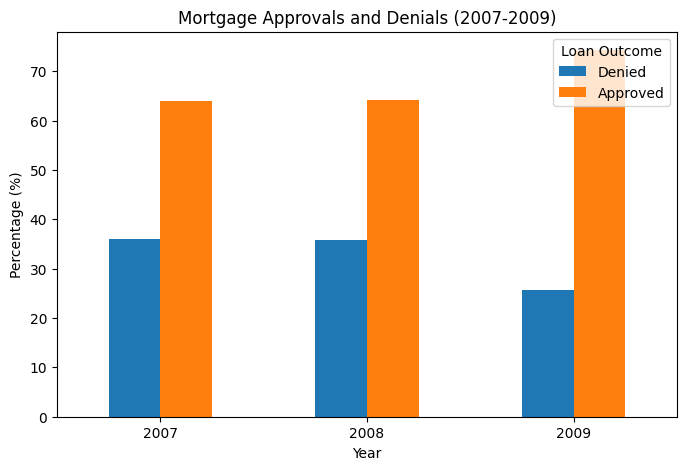

=== LOAN AMOUNT AND INCOME BY YEAR ===
This compares the median loan amounts and applicant incomes for each year (in thousands of dollars).


,loan_amount_000s,applicant_income_000s
as_of_year,,
2007,214.0,82.0
2008,200.0,74.0
2009,163.0,66.0


In [18]:
print("=== DATASET STRUCTURE AND DIMENSIONS ===")
print("This shows the number of rows, columns, data types, and memory usage.")


df.info()  # Rows, columns, memory usage, and data types
print("\nDataset shape (rows, columns):", df.shape)  # (number of rows, number of columns)


print("\n=== DATASET PREVIEW ===")
print("This shows examples of mortgage records in our dataset.")


print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

print("\n5 random rows:")
display(df.sample(5))



print("\n=== DATA QUALITY ===")
print("This checks for missing values and identical rows in the dataset.")

print("\nMissing values per column:")
display(df.isnull().sum()) # Total missing (NaN) values per column

print("\nNumber of duplicate rows:")
print(df.duplicated().sum()) # Total identical duplicate rows


print("\n=== STATISTICAL SUMMARIES ===")
print("This summarizes the numerical and categorical columns.")

print("\nNumerical columns:")
display(df.describe())
print("\nCategorical columns:")
display(df.describe(include="object"))


print("\n=== LOAN APPLICATION OUTCOMES ===")
print("This shows how many applications have each outcome.")

print("\nNumber of records for each outcome:")
display(df["action_taken"].value_counts())

print("\nNumber of unique outcomes:")
print(df["action_taken"].nunique())



print("=== MISSING VALUES IN SELECTED FEATURES ===")

missing_values = df_model[sample_features].isnull().sum()
missing_percent = df_model[sample_features].isnull().mean() * 100

print("\nMissing values:")
display(missing_values)


print("\nMissing percentages:")
display(missing_percent.round(2))


print("\n=== APPROVALS AND DENIALS BY YEAR ===")
print("This compares the number of approved and denied applications from 2007 to 2009.")

year_counts = pd.crosstab(
    df_model["as_of_year"],
    df_model["approved"]
)

year_counts = year_counts.rename(
    columns={0: "Denied", 1: "Approved"}
)
display(year_counts)



print("\n=== APPROVAL AND DENIAL PERCENTAGES BY YEAR ===")
print("This shows the percentage of approved and denied applications each year.")

year_percent = year_counts.div(
    year_counts.sum(axis=1), axis=0
) * 100

display(year_percent.round(2))


print("\n=== APPROVAL AND DENIAL GRAPH ===")

year_percent.plot(kind="bar", figsize=(8, 5))

plt.title("Mortgage Approvals and Denials (2007-2009)")
plt.xlabel("Year")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Loan Outcome")
plt.show()



print("=== LOAN AMOUNT AND INCOME BY YEAR ===")
print("This compares the median loan amounts and applicant incomes for each year (in thousands of dollars).")


display(
    df_model.groupby("as_of_year")[
        ["loan_amount_000s", "applicant_income_000s"]
    ].median()
)

## Risks and Limitations

Covered in memo

## Train/Validation/Test Strategy

In [19]:
time_col = "as_of_year"

print("=== TRAIN / VALIDATION / TEST STRATEGY ===")
train_df = df_model[df_model[time_col] == 2007].copy()
val_df = df_model[df_model[time_col] == 2008].copy()
test_df = df_model[df_model[time_col] == 2009].copy()

print(f"Training Set (2007):    {len(train_df):,} rows")
print(f"Validation Set (2008): {len(val_df):,} rows")
print(f"Test Set (2009):       {len(test_df):,} rows")

X_train = train_df[sample_features]
y_train = train_df[target_column]

X_val = val_df[sample_features]
y_val = val_df[target_column]

X_test = test_df[sample_features]
y_test = test_df[target_column]

print("\n=== FEATURE / TARGET SHAPES ===")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

=== TRAIN / VALIDATION / TEST STRATEGY ===
Training Set (2007):    26,486 rows
Validation Set (2008): 27,604 rows
Test Set (2009):       24,470 rows

=== FEATURE / TARGET SHAPES ===
X_train: (26486, 5)
y_train: (26486,)
X_val: (27604, 5)
y_val: (27604,)
X_test: (24470, 5)
y_test: (24470,)


## Primary Evaluation Metric

Covered in memo

## Feasibility and Compute Plan

Covered in memo